# 2. Scoring each provider on its own

Every provider gets the same LightGBM model with the same settings: its 100 m winds at the 9 points, plus hour of day and month in Central time. A monotonic constraint forces more wind to mean more power. Only the weather input differs, so score differences are differences in the weather.

- **Validation:** train before Jul 2025, predict Jul-Dec 2025 (used only to fit blend weights later).
- **Test:** train before 2026, predict 2026. Every score below is on 2026.
- **nMAE** is MAE as a percentage of a fixed reference capacity: the 99th percentile of output in the training years.

In [1]:
import os, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, "..")
from src import wind

DATA = "../data/wind"
FIG = "figures"
os.makedirs(FIG, exist_ok=True)
if not os.path.exists(f"{DATA}/wind_hourly.parquet"):
    raise SystemExit("Run the download first, from the repo root: EIA_API_KEY=... python -m src.wind_data")

INK, INK2, SURFACE, GRID = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})
pd.set_option("display.width", 160)

In [2]:
t = pd.read_parquet(f"{DATA}/wind_hourly.parquet")
P, start, skipped = wind.predict_all(t, wind.HUB)
print("skipped (no data):", skipped, "| common start:", f"{start:%Y-%m-%d}")
P.to_parquet(f"{DATA}/preds_hub.parquet")                 # used by notebooks 3 and 4

y = t.loc[t.index >= start, "wind_mw"]
cap = wind.reference_capacity(y, start)
base = wind.baselines(t[t.index >= start], y, start)
hours = (P[P.index >= wind.TEST_START].dropna().index
         .intersection(base.dropna().index).intersection(y.dropna().index))
yt, Pt, Bt = y[hours], P.loc[hours], base.loc[hours]
print(f"{len(hours):,} test hours in 2026; reference capacity {cap:,.0f} MW")

skipped (no data): ['GEM'] | common start: 2024-03-07
7,512 test hours in 2026; reference capacity 26,177 MW


In [3]:
rows = {k: wind.score(Pt[k], yt, cap, Bt) for k in Pt}
rows.update({k: wind.score(Bt[k], yt, cap) for k in Bt})
pd.DataFrame(rows).T.sort_values("MAE_MW").round(1)

,MAE_MW,nMAE_%,RMSE_MW,bias_MW,skill_vs_climatology_%,skill_vs_persistence_48h_%
ICON|d1,2003.6,7.7,2623.6,-328.5,82.7,89.1
ECMWF|d1,2010.3,7.7,2661.2,-449.4,82.2,88.8
GFS|d1,2067.4,7.9,2691.7,-311.4,81.8,88.6
ICON|d2,2215.6,8.5,2890.6,-534.7,79.0,86.8
ECMWF|d2,2217.6,8.5,2888.4,-498.4,79.0,86.8
GFS|d2,2380.2,9.1,3059.0,-212.8,76.5,85.2
climatology,5314.8,20.3,6308.7,-979.5,NaN,NaN
persistence_48h,6251.6,23.9,7956.8,12.8,NaN,NaN


**Day 1: is the gap to the best provider real?** A weekly block bootstrap resamples whole weeks, because errors come in streaks.

In [4]:
names = [k.split("|")[0] for k in Pt if k.endswith("|d1")]
d1 = Pt[[f"{n}|d1" for n in names]].set_axis(names, axis=1)
d2 = Pt[[f"{n}|d2" for n in names]].set_axis(names, axis=1)
best1, boot1 = wind.block_bootstrap_vs_best(d1.sub(yt, axis=0))
print("best day 1:", best1)
boot1.round(0)

best day 1: ICON


,MAE_minus_best_MW,CI_low,CI_high,clearly_worse
GFS,65.881503,-42.280266,173.75759,False
ICON,0.0,0.0,0.0,False
ECMWF,8.951237,-73.924311,93.195669,False


In [5]:
best2, boot2 = wind.block_bootstrap_vs_best(d2.sub(yt, axis=0))
print("best day 2:", best2)
boot2.round(0)

best day 2: ICON


,MAE_minus_best_MW,CI_low,CI_high,clearly_worse
GFS,165.817091,43.113278,285.36348,True
ICON,0.0,0.0,0.0,False
ECMWF,4.045789,-101.418887,119.810242,False


- **Day 1: statistically tied.** ICON is nominally best, but every 95% interval includes zero.
- **Day 2 separates them.** GFS is clearly worse, by about 166 MW. ICON and ECMWF hold up better with the extra day of lead time.

In [6]:
e1, e2 = d1.sub(yt, axis=0).abs(), d2.sub(yt, axis=0).abs()
pd.DataFrame({"day 1 nMAE %": e1.mean() / cap * 100, "day 2 nMAE %": e2.mean() / cap * 100,
              "day 2 worse by %": (e2.mean() / e1.mean() - 1) * 100}).round(1)

,day 1 nMAE %,day 2 nMAE %,day 2 worse by %
GFS,7.9,9.1,15.1
ICON,7.7,8.5,10.6
ECMWF,7.7,8.5,10.3


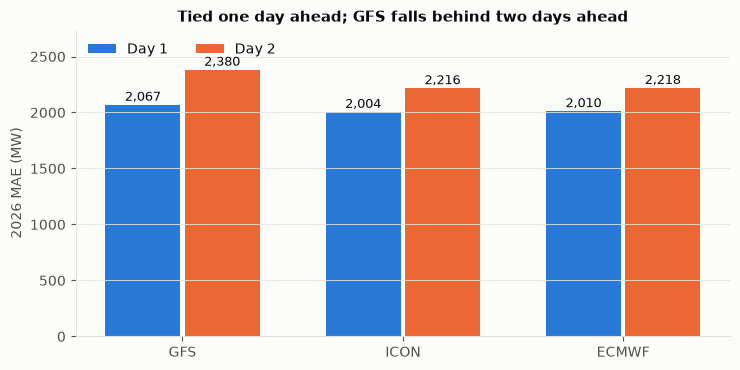

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
x = np.arange(len(names))
for i, (lead, e, color) in enumerate([("Day 1", e1, BLUE), ("Day 2", e2, ORANGE)]):
    vals = e.mean()
    bars = ax.bar(x + (i - 0.5) * 0.36, vals, width=0.34, color=color, label=lead)
    for b, v in zip(bars, vals):
        ax.annotate(f"{v:,.0f}", (b.get_x() + b.get_width() / 2, v), xytext=(0, 3),
                    textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(x, names)
ax.set_ylabel("2026 MAE (MW)")
ax.set_ylim(0, max(e1.mean().max(), e2.mean().max()) * 1.15)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=2)
ax.set_title("Tied one day ahead; GFS falls behind two days ahead")
fig.tight_layout()
fig.savefig(f"{FIG}/providers_by_lead.png", dpi=150)
plt.show()

**Where the errors are.** Slices use the *forecast* wind regime (known in advance), not what happened.

In [8]:
local = hours.tz_convert(wind.TZ)
print("Day-1 nMAE % by season:")
print(wind.by_slice(e1, wind.season_of(hours), cap).round(1).to_string())
print("\nDay-1 nMAE % by time of day (Central):")
print(wind.by_slice(e1, wind.part_of_day(hours), cap).round(1).to_string())
fleet_ws = pd.concat([t.loc[hours, wind.cols_for(t, p, "d1")].mean(axis=1)
                      for p in wind.HUB.values() if wind.has_data(t, p)], axis=1).mean(axis=1)
regime = pd.cut(fleet_ws, [0, 5, 8, 11, 40], labels=["calm <5", "low 5-8", "mid 8-11", "high >11 m/s"])
tab = wind.by_slice(e1, regime, cap).round(1)
tab["hours"] = regime.value_counts()
print("\nDay-1 nMAE % by forecast wind regime (m/s):")
print(tab.to_string())

Day-1 nMAE % by season:
        GFS  ICON  ECMWF
Fall    7.3   7.4    7.0
Spring  8.1   8.3    8.3
Summer  7.7   7.1    7.2
Winter  8.6   7.8    8.2

Day-1 nMAE % by time of day (Central):
                 GFS  ICON  ECMWF
night 0-6        8.7   8.0    8.3
morning 6-12     7.4   7.5    7.4
afternoon 12-18  6.6   6.7    6.7
evening 18-24    8.9   8.4    8.4

Day-1 nMAE % by forecast wind regime (m/s):
              GFS  ICON  ECMWF  hours
calm <5       5.2   5.5    5.6    859
low 5-8       8.3   8.2    8.2   3550
mid 8-11      8.6   7.8    7.8   2598
high >11 m/s  6.3   6.7    6.6    505


- **Afternoons are easiest, nights and evenings hardest:** stable nights bring strong, changing shear and low-level jets.
- **Low and mid-curve winds are hardest,** as the physics notebook predicts: errors cost most on the steep part of the power curve.
- **Every provider under-forecasts** (negative bias), consistent with fleet growth after the training period.

## Height: does hub-height wind matter?

The same comparison with surface winds: GFS at 100 m against pure GFS at 10 m (`gfs_global`), plus JMA and UKMO, which only offer 10 m. These columns come from `python -m src.wind_data --surface`, and this cell skips itself if they aren't in the table. From my run, 2026, day 1:

| Input | nMAE | |
|---|---|---|
| GFS 100 m | 7.8% | |
| GFS 10 m | 9.1% | 17% worse; bootstrap: clearly worse (+271 to +424 MW) |
| GFS 100 m, day 2 | 9.0% | about the same as 10 m on day 1 |

Losing the hub-height variable cost about as much as an extra day of lead time. The penalty was largest at night (10.5% vs. 8.5%) and in winter (10.6% vs. 8.5%), the stable conditions where surface and hub-height winds come apart.

In [9]:
if wind.has_data(t, "ws10_gfs_global"):
    Ph, _, _ = wind.predict_all(t, wind.HEIGHT)
    th = Ph[Ph.index >= wind.TEST_START].dropna().index.intersection(t["wind_mw"].dropna().index)
    print(pd.DataFrame({k: wind.score(Ph.loc[th, k], t.loc[th, "wind_mw"], cap) for k in Ph}).T.round(1))
else:
    print("10 m columns not in this table; run `python -m src.wind_data --surface` to reproduce the height experiment.")

10 m columns not in this table; run `python -m src.wind_data --surface` to reproduce the height experiment.
